n=100   | list:   0.881 мкс | set:  0.039 мкс | set быстрее в   22.7 раз
n=1000  | list:  10.462 мкс | set:  0.034 мкс | set быстрее в  309.5 раз
n=10000 | list: 108.117 мкс | set:  0.034 мкс | set быстрее в 3194.5 раз


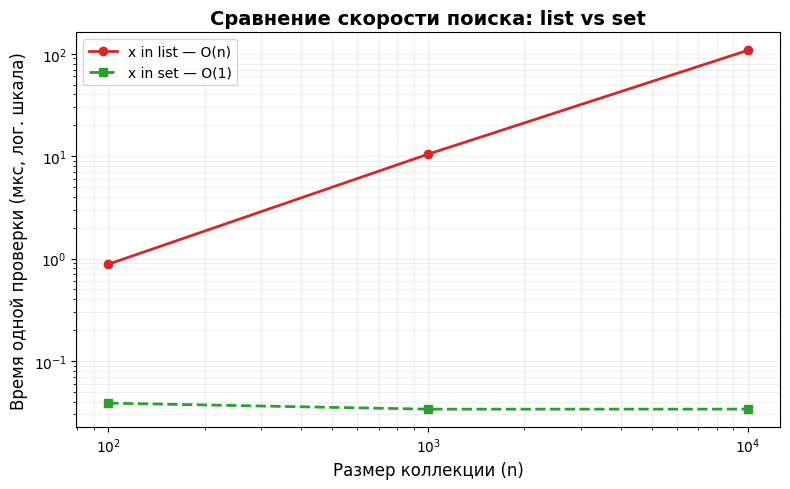

In [5]:
import timeit
import matplotlib.pyplot as plt

# Задача 1

sizes = [100, 1000, 10000]
number = 1000
repeat = 5
target = -1

times_list = []
times_set = []

for n in sizes:
    # 1. Подготовка данных
    data_list = list(range(n))
    data_set = set(range(n))

    raw_list = timeit.repeat(
        stmt="target in data_list",
        globals={"target": target, "data_list": data_list},
        number=number,
        repeat=repeat
    )
    raw_set = timeit.repeat(
        stmt="target in data_set",
        globals={"target": target, "data_set": data_set},
        number=number,
        repeat=repeat
    )
    t_list = min(raw_list) / number * 1_000_000
    t_set = min(raw_set) / number * 1_000_000

    times_list.append(t_list)
    times_set.append(t_set)

    speedup = t_list / t_set
    print(f"n={n:<5} | list: {t_list:7.3f} мкс | set: {t_set:6.3f} мкс | set быстрее в {speedup:6.1f} раз")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(sizes, times_list, "o-", color="tab:red", linewidth=2, label="x in list — O(n)")
ax.plot(sizes, times_set, "s--", color="tab:green", linewidth=2, label="x in set — O(1)")

ax.set_yscale("log")
ax.set_xscale("log")

ax.set_xlabel("Размер коллекции (n)", fontsize=12)
ax.set_ylabel("Время одной проверки (мкс, лог. шкала)", fontsize=12)
ax.set_title("Сравнение скорости поиска: list vs set", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, which="both", alpha=0.2)

plt.tight_layout()
plt.show()
